# Assignment 64 — Week 7, Day 4
## Topic: Deep Learning — CNN on CIFAR-10

**Objective:** Perform CNN classification on the CIFAR-10 dataset.

**Reference:** https://www.analyticsvidhya.com/blog/2020/02/learn-image-classification-cnn-convolutional-neural-networks-3-datasets/

**CIFAR-10** is a classic image classification data set: 60,000 colour images of 32 × 32 pixels in 10 classes (airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck), with 50,000 for training and 10,000 for testing.

Following the Analytics Vidhya tutorial, this notebook loads the data, builds a Convolutional Neural Network with Keras, trains it, and evaluates it with accuracy, a confusion matrix and example predictions.

**Notes**

- Keras downloads CIFAR-10 automatically the first time (about 170 MB) and caches it in `~/.keras/datasets`.
- Training takes roughly 10–20 minutes on a laptop CPU, so the cells below share variables and must be run **in order**.

**Diagram:** CIFAR-10 images are small colour photos of real objects.

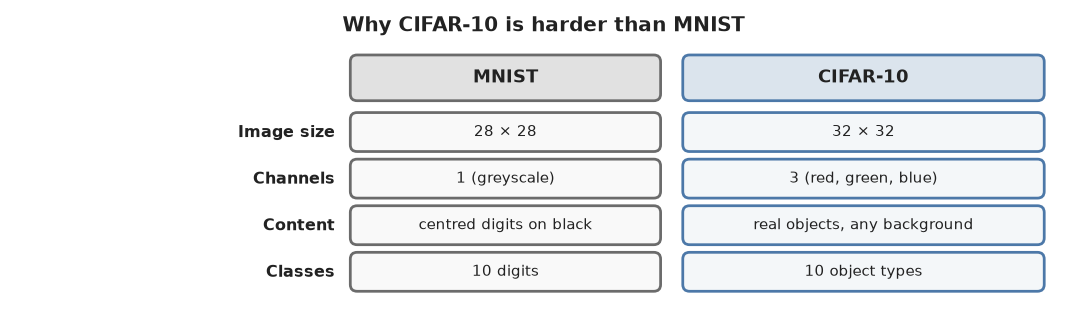

**Set up TensorFlow and Keras**

In [1]:
import os
import logging

# Hide TensorFlow's start-up log messages so the outputs stay readable
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
logging.getLogger("tensorflow").setLevel(logging.ERROR)

import numpy as np
import tensorflow as tf
from tensorflow import keras

tf.get_logger().setLevel(logging.ERROR)
keras.utils.set_random_seed(42)  # makes the results repeatable
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


**Explanation:** The setup cell imports NumPy, TensorFlow and Keras, hides TensorFlow's log messages and fixes the random seed.

**Load the CIFAR-10 data**

In [2]:
from tensorflow import keras

(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

print("x_train:", x_train.shape, "| y_train:", y_train.shape)
print("x_test: ", x_test.shape, "| y_test: ", y_test.shape)
print("Pixel range:", x_train.min(), "to", x_train.max())
print("Images per class in training set:", np.bincount(y_train.ravel()))

x_train: (50000, 32, 32, 3) | y_train: (50000, 1)
x_test:  (10000, 32, 32, 3) | y_test:  (10000, 1)
Pixel range: 0 to 255
Images per class in training set: [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


**Explanation:** Each image is 32 × 32 pixels with 3 colour channels, stored as numbers from 0 to 255. The labels are class numbers 0–9, and every class has exactly 5,000 training images, so the data is balanced.

**Look at some images**

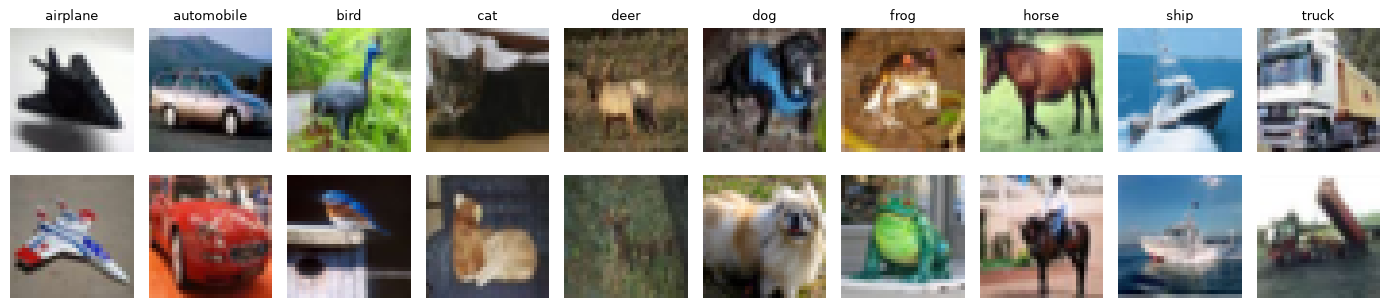

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 10, figsize=(14, 3.4))
for class_id in range(10):
    examples = np.where(y_train.ravel() == class_id)[0][:2]
    for row, idx in enumerate(examples):
        axes[row, class_id].imshow(x_train[idx])
        axes[row, class_id].axis("off")
    axes[0, class_id].set_title(class_names[class_id], fontsize=9)
plt.tight_layout()
plt.show()

**Explanation:** Two training images per class. They are tiny, low-resolution photos with varied backgrounds, poses and lighting, which makes them much harder to classify than handwritten digits.

**Prepare the data**

In [4]:
x_train_n = x_train.astype("float32") / 255.0
x_test_n = x_test.astype("float32") / 255.0

y_train_1hot = keras.utils.to_categorical(y_train, 10)
y_test_1hot = keras.utils.to_categorical(y_test, 10)

print(x_train_n.shape, y_train_1hot.shape)
print("First label:", y_train[0][0], "->", y_train_1hot[0])

(50000, 32, 32, 3) (50000, 10)
First label: 6 -> [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]


**Explanation:** Pixel values are scaled to the range 0–1, which helps training. The labels are one-hot encoded: class 6 (frog) becomes a vector of ten values with a 1 in position 6.

**Diagram:** Stacked convolution and pooling blocks learn features from the colour images, then dense layers classify them.

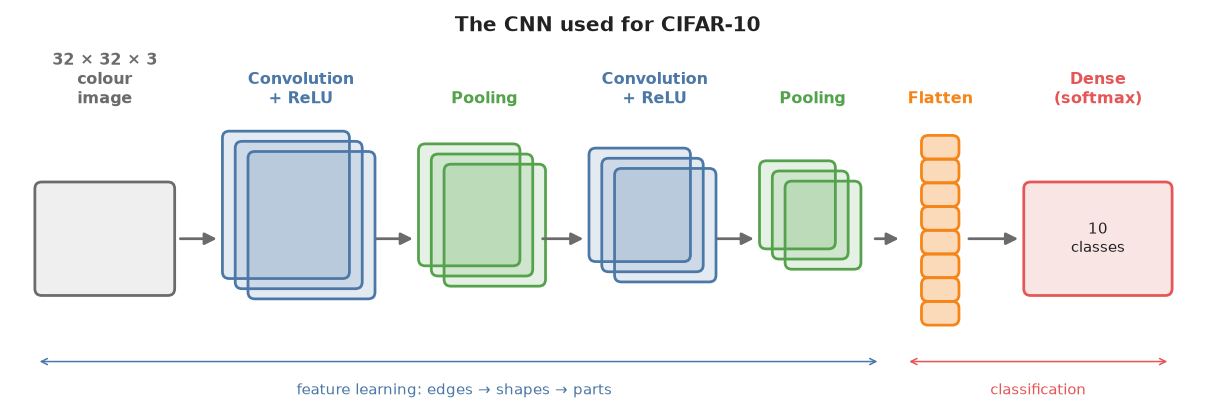

**Build the CNN**

In [5]:
from tensorflow.keras import layers

model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax"),
])

model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,048,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,116,970 (4.26 MB)

 Trainable params: 1,116,970 (4.26 MB)

 Non-trainable params: 0 (0.00 B)

**Explanation:** Two blocks of two Conv2D layers learn features ('same' padding keeps the 32 × 32 size within a block), MaxPooling halves the size after each block, and Dropout reduces overfitting. The Dense layers at the end combine the features, and softmax gives a probability for each class.

**Train the CNN**

In [6]:
history = model.fit(
    x_train_n, y_train_1hot,
    batch_size=128,
    epochs=12,
    validation_split=0.1,
    verbose=2,
)

Epoch 1/12


352/352 - 68s - 192ms/step - accuracy: 0.3966 - loss: 1.6428 - val_accuracy: 0.5642 - val_loss: 1.2163


Epoch 2/12


352/352 - 66s - 188ms/step - accuracy: 0.5629 - loss: 1.2204 - val_accuracy: 0.6524 - val_loss: 0.9888


Epoch 3/12


...

352/352 - 68s - 195ms/step - accuracy: 0.7761 - loss: 0.6348 - val_accuracy: 0.7836 - val_loss: 0.6480


Epoch 11/12


352/352 - 68s - 193ms/step - accuracy: 0.7832 - loss: 0.6128 - val_accuracy: 0.7796 - val_loss: 0.6462


Epoch 12/12


352/352 - 74s - 210ms/step - accuracy: 0.7924 - loss: 0.5802 - val_accuracy: 0.7854 - val_loss: 0.6499


**Explanation:** The model trains for 12 epochs in batches of 128 images, holding back 10% of the training images to check progress on unseen data after each epoch.

**Learning curves**

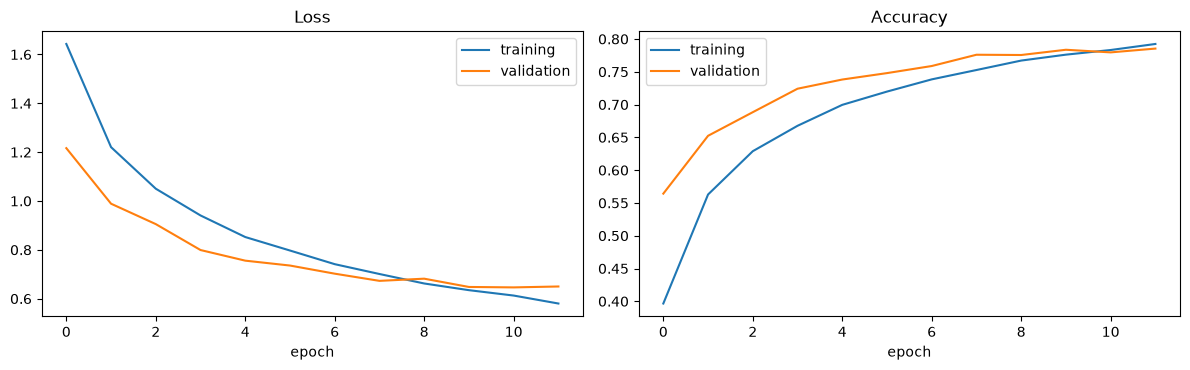

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(history.history["loss"], label="training")
axes[0].plot(history.history["val_loss"], label="validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(history.history["accuracy"], label="training")
axes[1].plot(history.history["val_accuracy"], label="validation")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout()
plt.show()

**Explanation:** Training and validation accuracy rise together over the epochs. If the training accuracy kept rising while the validation accuracy fell, the model would be overfitting; the Dropout layers help prevent that.

**Evaluate on the test set**

In [8]:
test_loss, test_acc = model.evaluate(x_test_n, y_test_1hot, verbose=0)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")
print("Random guessing would score about 0.10")

Test accuracy: 0.7771
Test loss: 0.6748
Random guessing would score about 0.10


**Explanation:** The test set contains 10,000 images the model never saw. The accuracy here is the honest measure of how well the CNN classifies new images.

**Confusion matrix and per-class accuracy**

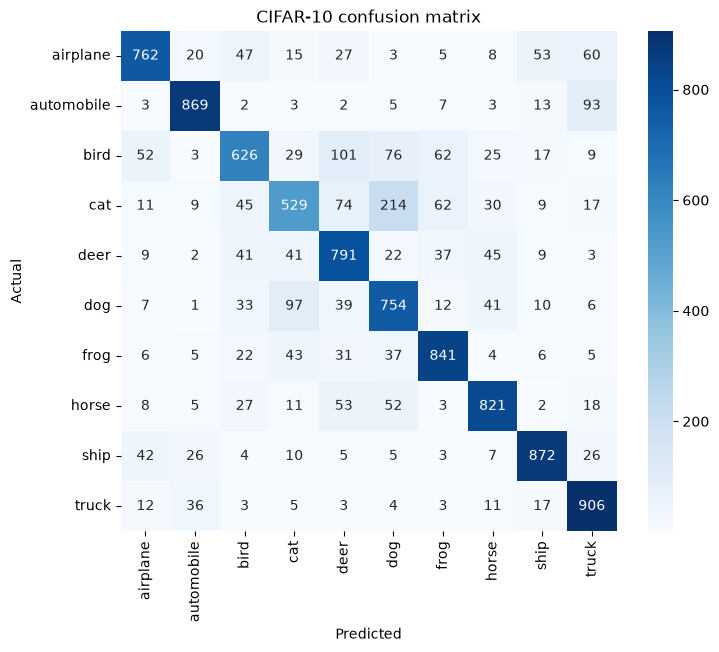

truck      0.91
ship       0.87
automobile 0.87
frog       0.84
horse      0.82
deer       0.79
airplane   0.76
dog        0.75
bird       0.63
cat        0.53


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

y_pred = model.predict(x_test_n, verbose=0).argmax(axis=1)
y_true = y_test.ravel()

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("CIFAR-10 confusion matrix")
plt.show()

per_class = cm.diagonal() / cm.sum(axis=1)
for name, acc in sorted(zip(class_names, per_class), key=lambda t: -t[1]):
    print(f"{name:10} {acc:.2f}")

**Explanation:** The diagonal shows correct predictions for each class. Vehicles are recognised best (truck about 91%, ship and automobile about 87%), while animals are harder: cats (about 53%) and birds (about 63%) score lowest, and the matrix shows which classes they are mistaken for, such as cats predicted as dogs.

**Example predictions**

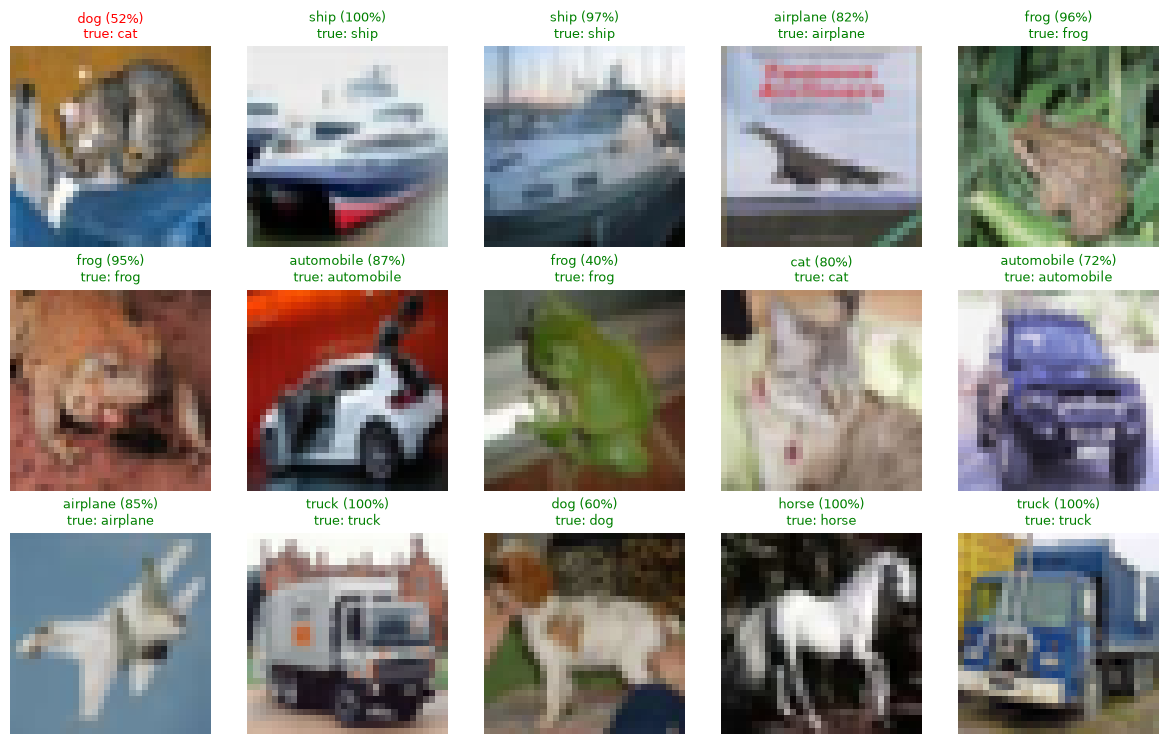

In [10]:
import matplotlib.pyplot as plt

probabilities = model.predict(x_test_n[:15], verbose=0)

fig, axes = plt.subplots(3, 5, figsize=(12, 7.5))
for ax, img, p, true in zip(axes.flat, x_test[:15], probabilities, y_test[:15].ravel()):
    pred = p.argmax()
    ax.imshow(img)
    ax.set_title(f"{class_names[pred]} ({p.max():.0%})\ntrue: {class_names[true]}",
                 color="green" if pred == true else "red", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Explanation:** Each title shows the predicted class with the model's confidence, and the true class below it. Green titles are correct; red titles are mistakes.

## Observation

- CIFAR-10 has 60,000 small 32 × 32 colour images in 10 balanced classes, which is much harder than MNIST.
- Pixels are scaled to 0–1 and labels one-hot encoded before training.
- The CNN stacks two convolution + pooling blocks with dropout, then dense layers with a softmax output.
- After 12 epochs on a CPU the model reaches about 78% test accuracy, far above the 10% of random guessing.
- The confusion matrix shows vehicles are recognised best (truck about 91%), while cats (about 53%) and birds (about 63%) are the hardest classes.

## Conclusion

A CNN learns useful features straight from colour images and classifies real-world objects reasonably well after a short training run. Longer training, data augmentation (flips, shifts) or deeper architectures would push the accuracy higher.